/var/folders/m9/_g3wndrn04d80ys2382r700r0000gn/T/ipykernel_74130/599864222.py:32: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  df = df.append({"Scenario": scenario, "Utilisation %": percent, "Cost": cost}, ignore_index=True)
/var/folders/m9/_g3wndrn04d80ys2382r700r0000gn/T/ipykernel_74130/599864222.py:32: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  df = df.append({"Scenario": scenario, "Utilisation %": percent, "Cost": cost}, ignore_index=True)
/var/folders/m9/_g3wndrn04d80ys2382r700r0000gn/T/ipykernel_74130/599864222.py:32: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  df = df.append({"Scenario": scenario, "Utilisation %": percent, "Cost": cost}, ignore_index=True)
/var/folders/m9/_g3wndrn04d80ys2382r700r0000gn/T/ipyker

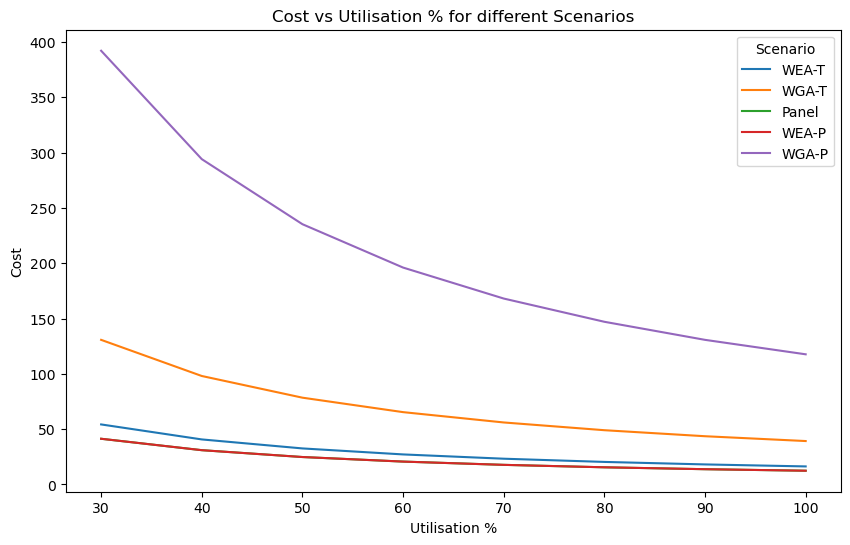

In [4]:
# Copyright 2026 Dylan. SPDX-License-Identifier: Apache-2.0
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Define the instrument cost
X = 343507.304

# Define utilisation amounts
utilisation = {
    "WGS 30x": 2920,
    "WES 50x": 44165,
    "WES 80x": 27740,
}

# Define the utilisation cost for each scenario
scenarios = {
    "WEA-T": {"WES 80x": 1, "WES 50x": 2},
    "WGA-T": {"WGS 30x": 3},
    "Panel": {"WES 80x": 1},
    "WEA-P": {"WES 80x": 1},
    "WGA-P": {"WGS 30x": 1},
}

# Create DataFrame
df = pd.DataFrame()

for scenario, utils in scenarios.items():
    for percent in range(30, 101, 10):
        cost = 0
        for util, n in utils.items():
            cost += X / ((utilisation[util] * n) * percent / 100)
        df = df.append(
            {"Scenario": scenario, "Utilisation %": percent, "Cost": cost},
            ignore_index=True,
        )

# Convert 'Utilisation %' column to int for better visualization
df["Utilisation %"] = df["Utilisation %"].astype(int)

# Plotting
plt.figure(figsize=(10, 6))
sns.lineplot(data=df, x="Utilisation %", y="Cost", hue="Scenario")
plt.title("Cost vs Utilisation % for different Scenarios")
plt.show()